In [1]:
import io
import chess.pgn
import pandas as pd
import numpy as np
import requests
import zstandard 
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score, cross_val_predict, KFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone, BaseEstimator, TransformerMixin
from stockfish import Stockfish
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, log_loss
from concurrent.futures import ThreadPoolExecutor
import os
import matplotlib.pyplot as plt
from functools import partial 
import time
import ast

In [2]:
SF_PATH = r"C:\Users\yazid\Downloads\stockfish-windows-x86-64-universal\stockfish\stockfish-windows-x86-64-universal.exe"
N_WORKERS = max(1, (os.cpu_count() or 2) // 2)


In [3]:
def game_lengths(url, n_games=20000):
    resp = requests.get(url, stream=True)
    stream = io.TextIOWrapper(zstandard.ZstdDecompressor().stream_reader(resp.raw), encoding='utf-8')
    rows = []
    while len(rows) < n_games:
        game = chess.pgn.read_game(stream)
        if game is None:
            break
        if game.headers.get('Result') not in ('1-0', '0-1'):
            continue
        rows.append({'plies': game.end().ply(), 'tc': game.headers.get('TimeControl')})
    resp.close()
    return pd.DataFrame(rows)

def eval_chunks_depth(fens, depth=10):
    sf = Stockfish(path=SF_PATH, depth=depth, parameters={'Threads': 1, 'Hash': 64})
    return [evaluate_position(sf, fen) for fen in fens]

def evaluate_position(stockfish, fen):
    board = chess.Board(fen)
    if board.is_checkmate():
        return -10000 if board.turn == chess.WHITE else 10000
    if board.is_game_over():
        return 0
    stockfish.set_fen_position(board.fen())
    result = stockfish.get_evaluation()
    if result['type'] == 'cp':
        value = result['value']
    else:
        value = 10000 if result['value'] > 0 else -10000
    return value if board.turn == chess.WHITE else -value

In [4]:
RANDOM_STATE = 42
CV = 5

In [ ]:
PIECE_VALUE = {
    chess.PAWN: 1, chess.KNIGHT: 3, chess.BISHOP: 3, chess.ROOK: 5, chess.QUEEN: 9
}

START_SQUARES = {
    chess.WHITE: {chess.KNIGHT: {chess.B1, chess.G1}, chess.BISHOP: {chess.C1, chess.F1}, chess.QUEEN: {chess.D1}}, chess.BLACK: {chess.KNIGHT: {chess.B8, chess.G8}, chess.BISHOP: {chess.C8, chess.F8}, chess.QUEEN: {chess.D8}}
}

def developed(board, color):
    count = 0
    for piece_type in (chess.KNIGHT, chess.BISHOP):
        for sq in board.pieces(piece_type, color):
            if sq not in START_SQUARES[color][piece_type]:
                count += 1
    return count

def queen_out(board, color): 
    return int(any(sq not in START_SQUARES[color][chess.QUEEN] for sq in board.pieces(chess.QUEEN, color)))

def mobility(board, color):
    b = board.copy(stack=False)
    b.turn = color
    b.ep_square = None
    return b.legal_moves.count()

def material(board, color):
    return sum(PIECE_VALUE.get(p.piece_type, 0)
        for p in board.piece_map().values() if p.color == color)

def extract_features(game, n_moves=15):
    h = game.headers
    base, inc = h['TimeControl'].split('+')
    base_sec, inc_sec = int(base), int(inc)
    board = game.board()
    clocks = {chess.WHITE: float('nan'), chess.BLACK: float('nan')}
    mid_clocks = {chess.WHITE: float('nan'), chess.BLACK: float('nan')}
    plies = 0
    last_ply = 2 * n_moves
    mid_ply = 2 * (n_moves // 2)
    last_node = None
    white_castled = 0
    black_castled = 0
    for node in game.mainline():
        mover = board.turn
        if board.is_castling(node.move):
            if mover == chess.WHITE:
                white_castled = 1
            else:
                black_castled = 1
        board.push(node.move)
        c = node.clock()
        if c is not None:
            clocks[mover] = c
        plies += 1
        last_node = node
        if plies == mid_ply:
            mid_clocks = clocks.copy()
        if plies == last_ply:
            break
    if plies < 2 * n_moves:
        return None
    if last_node.is_end():
        return None
    if board.is_game_over():
        return None
    w_elo, b_elo = int(h['WhiteElo']), int(h['BlackElo'])
    w_spent = (base_sec + (n_moves * inc_sec)) - clocks[chess.WHITE]
    b_spent = (base_sec + (n_moves * inc_sec)) - clocks[chess.BLACK]
    return {
        'game_id': h['Site'].split('/')[-1],
        'date': h['UTCDate'], 'time': h['UTCTime'],
        'white': h['White'], 'black': h['Black'], 
        'white_elo': w_elo, 'black_elo': b_elo,
        'elo_diff': w_elo - b_elo,
        'base_sec': int(base), 'inc_sec': int(inc),
        'material_diff': material(board, chess.WHITE) - material(board, chess.BLACK), 'white_clock': clocks[chess.WHITE],
        'black_clock': clocks[chess.BLACK], 'clock_diff': clocks[chess.WHITE] - clocks[chess.BLACK],
        'white_clock_mid': mid_clocks[chess.WHITE], 'black_clock_mid': mid_clocks[chess.BLACK], 
        'white_spent_second_half': mid_clocks[chess.WHITE] - clocks[chess.WHITE], 'black_spent_second_half': mid_clocks[chess.BLACK] - clocks[chess.BLACK],
        'white_sec_per_move': w_spent / n_moves,
        'black_sec_per_move': b_spent / n_moves,
        'sec_per_move_diff': (w_spent - b_spent) / n_moves,
        'white_castled': white_castled,
        'black_castled': black_castled,
        'developed_white': developed(board, chess.WHITE),
        'developed_black': developed(board, chess.BLACK),
        'queen_out_white': queen_out(board, chess.WHITE),
        'queen_out_black': queen_out(board, chess.BLACK),
        'mobility_white': mobility(board, chess.WHITE),
        'mobility_black': mobility(board, chess.BLACK),
        'fen_end': board.fen(),
        'result': h['Result']
    }

def read_games(url, max_games=20000, n_moves=15):
    resp = requests.get(url, stream=True)
    rows = []
    stream = io.TextIOWrapper(zstandard.ZstdDecompressor().stream_reader(resp.raw), encoding='utf-8')
    while len(rows) < max_games:
        game = chess.pgn.read_game(stream)
        if game is None:
            break
        try:
            features = extract_features(game, n_moves)
            if features is not None:
                rows.append(features)
        except (KeyError, ValueError):
            continue
    resp.close()
    return pd.DataFrame(rows)

def add_stockfish_eval_parallel(df):
    fens = df['fen_end'].tolist()
    chunks = [fens[i::N_WORKERS] for i in range(N_WORKERS)]
    with ThreadPoolExecutor(N_WORKERS) as ex:
        results = list(ex.map(eval_chunks_depth, chunks))
    out = [None] * len(fens)
    for i, res in enumerate(results):
        out[i::N_WORKERS] = res
    df['eval_end'] = out
    return df

def add_feature(df):
    df['white_clock_rel'] = df['white_clock'] / df['base_sec']
    df['black_clock_rel'] = df['black_clock'] / df['base_sec']
    df['clock_diff_rel'] = df['clock_diff'] / df['base_sec']
    df['elo_mean'] = (df['white_elo'] + df['black_elo']) / 2
    elo_gap = df['elo_diff'].clip(-500, 500)
    level = (df['elo_mean'] - df['elo_mean'].mean()) / df['elo_mean'].std()
    df['eval_x_level'] = df['eval_end'] * level
    df['eval_x_gap'] = df['eval_end'] * (elo_gap / 500)
    df['developed_diff'] = df['developed_white'] - df['developed_black']
    df['mobility_diff'] = df['mobility_white'] - df['mobility_black']
    df['has_increment'] = (df['inc_sec'] > 0).astype(int)
    df['log_base_sec'] = np.log1p(df['base_sec'])
    return df

In [6]:
# lengths = game_lengths(url='https://database.lichess.org/standard/lichess_db_standard_rated_2017-04.pgn.zst')
# lengths['moves'] = (lengths['plies'] + 1) // 2

# print(lengths['moves'].describe())
# for n in [10, 15, 20, 25, 30]:
#     print(n, 'moves: shares of decisive games that ended after: ', round((lengths['moves'] > n).mean(), 3))
    

In [7]:
# df = read_games('https://database.lichess.org/standard/lichess_db_standard_rated_2017-04.pgn.zst', 50000, 20)
# df = df[(df['base_sec'] > 0) & (df['result'].isin(['1-0', '0-1']))].copy()
# df['white_won'] = (df['result'] == '1-0').astype(int)
# df = add_stockfish_eval_parallel(df)
# df.to_csv('games_2017-04m20_5000.csv', index=False)

In [ ]:
def get_df():
    df = pd.read_csv('games_2017-04m20_5000.csv')
    df = df[df['base_sec'] > 0].copy()
    df['eval_end'] = df['eval_end'].clip(-1000, 1000)
    df = add_feature(df)
    df = df.replace([np.inf, -np.inf], np.nan)
    df = df.sort_values(by=['date', 'time']).reset_index(drop=True)
    return df
df = get_df()

In [9]:
cut = int(len(df) * 0.8)
df_train = df.iloc[:cut].copy()
df_test = df.iloc[cut:].copy()

In [10]:
X_train = df_train.drop(columns=['result', 'white_won'])
y_train = df_train['white_won']
X_test = df_test.drop(columns=['result', 'white_won'])
test_id = df_test['game_id']
y_test = df_test['white_won']

In [11]:
COLUMN_TYPE = {}

for col in df.columns:
    COLUMN_TYPE[col] = 'num'


In [12]:
def split_by_type(columns):
    result = {'num': []}
    for col in columns:
        t = COLUMN_TYPE[col]
        result[t].append(col)
    return result

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [13]:
models =  {
    'xgboost': XGBClassifier(random_state=RANDOM_STATE),
    'logistic': LogisticRegression(max_iter=10000),
    'catboost': CatBoostClassifier(random_state=RANDOM_STATE, verbose=False, allow_writing_files=None), 
    'random_forest': RandomForestClassifier(random_state=RANDOM_STATE)
}

param_distributions = {
    'xgboost': {'model__max_depth': [2,3,4,5], 'model__learning_rate': [0.01, 0.03, 0.1], 'model__n_estimators': [100,300,600], 'model__subsample': [0.7, 0.85, 1.0], 'model__colsample_bytree': [0.6, 0.8, 1.0], 'model__min_child_weight': [1,3,5]},
    'logistic': {'model__C': [0.01, 0.1, 1, 10]},
    'catboost': {'model__max_depth': [3,4,5,6], 'model__learning_rate': [0.03, 0.05, 0.1], 'model__iterations': [300,500,1000], 'model__l2_leaf_reg': [1,3,5,10]},
    'random_forest': {'model__max_depth': [3,4,5,6,8, None], 'model__min_samples_leaf': [1,2,4,8,12], 'model__min_samples_split': [2,5,10,20], 'model__max_features': ['sqrt', 'log2', 0.5], 'model__max_samples': [0.6,0.8,None]}
}

family = {
    'xgboost': 'trees',
    'logistic': 'linear',
    'catboost': 'trees', 
    'random_forest': 'trees'
}


In [14]:
def get_dummy_prediction(X_tr, y_tr):
    dummy = DummyClassifier(strategy='constant', constant=1, random_state=RANDOM_STATE)
    score = -cross_val_score(estimator=dummy, X=X_tr, y=y_tr, cv=cv, scoring='neg_log_loss', n_jobs=-1)
    return score

def build_preprocessor(num_cols):
    num_pipeline = Pipeline(steps=[('impute', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
    return ColumnTransformer(transformers=[('num', num_pipeline, num_cols)])

def build_pipeline(preprocessor, model):
    return Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])

def evaluate_model(EXPERIMENT_COLUMNS, model_name, model, X_tr, y_tr):
    parts = split_by_type(EXPERIMENT_COLUMNS)
    preprocessor = build_preprocessor(parts['num'])
    pipeline = build_pipeline(preprocessor, model)
    score = cross_val_score(estimator=pipeline, X=X_tr, y=y_tr, cv=cv, scoring='neg_log_loss', n_jobs=-1)
    return {'model': model_name, 'score': -score.mean()}

def tune_model(COLUMNS, model, model_name, param_distributions, X_tr, y_tr, n_iter=30):
    parts = split_by_type(COLUMNS)
    preprocessor = build_preprocessor(parts['num'])
    pipeline = build_pipeline(preprocessor, model)
    search = RandomizedSearchCV(estimator=pipeline, param_distributions=param_distributions, n_iter=n_iter, n_jobs=-1, scoring='neg_log_loss', return_train_score=True, refit=False, random_state=RANDOM_STATE, error_score='raise')
    search.fit(X_tr, y_tr)
    results = pd.DataFrame(search.cv_results_)
    results['model'] = model_name
    results['train_log_loss'] = -results['mean_train_score']
    results['validation_log_loss'] = -results['mean_test_score']
    best_result = select_best_result(results)
    return search, results, best_result

def select_best_result(results):
    if results.empty:
        raise ValueError('result is empty')
    else:
        return results.loc[results['validation_log_loss'].idxmin()]

def score_log_loss(chosen, model, X_tr, y_tr):
    parts = split_by_type(chosen)
    preprocessor = build_preprocessor(num_cols=parts['num'])
    pipeline = build_pipeline(preprocessor, model)
    score = cross_val_score(pipeline, X_tr, y_tr, cv=cv, scoring='neg_log_loss', n_jobs=-1)
    return -score.mean()

def score_columns(chosen, model, X_tr, y_tr):
    parts = split_by_type(chosen)
    preprocessor = build_preprocessor(num_cols=parts['num'])
    pipeline = build_pipeline(preprocessor=preprocessor, model=model)
    score = cross_val_score(estimator=pipeline, X=X_tr, y=y_tr, cv=cv, scoring='accuracy', n_jobs=-1)
    return score.mean()

In [15]:
# sample = df.sample(2000, random_state=RANDOM_STATE).copy()
# fens = sample['fen_end'].tolist()
# chunks = [fens[i::N_WORKERS] for i in range(N_WORKERS)]
 
# t0 = time.time()
# worker_fn = partial(eval_chunks_depth, depth=16)
# with ThreadPoolExecutor(N_WORKERS) as ex:
#     results = list(ex.map(worker_fn, chunks))
# out = [None] * len(fens)
# for i, res in enumerate(results):
#     out[i::N_WORKERS] = res
# print(f'2000 positions at depth 16 took {time.time() - t0:.1f} sec')

# d10 = sample['eval_end'].clip(-1000,1000)
# d16 = pd.Series(out, index=sample.index).clip(-1000, 1000)

# corr = d10.corr(d16)
# mad = (d10-d16).abs().mean()
# print(f"Pearson corr: {corr:.1f}")
# print(f"Mean absolute difference: {mad:.1f}")

# plt.figure(figsize=(5,5))
# plt.scatter(d10, d16, alpha=0.15, s=10)
# plt.plot([-1000,1000], [-1000, 1000], 'r--', linewidth=1)
# plt.xlabel('Depth 10 eval (cp)')
# plt.ylabel('Depth 16 eval (cp)')
# plt.title(f'Depth 10 vs 16 (r = {corr:.3f})')
# plt.grid(True, alpha=0.3)
# plt.show()

In [16]:
# val_cut = int(len(X_train) * 0.8)
# sub_tr_X, sub_val_X = X_train.iloc[:val_cut], X_train.iloc[val_cut:]
# sub_tr_y, sub_val_y = y_train.iloc[:val_cut], y_train.iloc[val_cut:]
# ALL_CANDIDATES = [col for col in df_train.columns if col not in ['date', 'game_id', 'time', 'white', 'black', 'fen_end', 'result', 'white_won']]
# remaining = ALL_CANDIDATES.copy()
# history = []

# while len(remaining) >= 1:
#     cb = CatBoostClassifier(iterations=400, random_state=RANDOM_STATE, verbose=False, thread_count=-1)
#     pipe = build_pipeline(build_preprocessor(remaining), cb)
#     pipe.fit(sub_tr_X, sub_tr_y)
#     probs = pipe.predict_proba(sub_val_X)[:, 1]
#     ll = log_loss(sub_val_y, probs)
#     acc = accuracy_score(sub_val_y, (probs > 0.5).astype(int))
#     importances = pipe.named_steps['model'].feature_importances_
#     worst_col = remaining[int(np.argmin(importances))]
#     history.append({
#         'n_cols': len(remaining),
#         'val_ll': ll,
#         'val_acc': acc,
#         'cols': remaining.copy(),
#         'dropped_next': worst_col
#     })
#     remaining.remove(worst_col)
# hist_df = pd.DataFrame(history)
# best_row = hist_df.loc[hist_df['val_ll'].idxmin()]
# FINAL_COLUMNS = best_row['cols']

# print(f'Best log loss: {best_row['val_ll']:.4f}, Best accuraccy: {best_row['val_acc']:.4f}, {best_row['n_cols']} cols')
# print("FINAL COLUMNS: ", FINAL_COLUMNS)


In [17]:
FINAL_COLUMNS = pd.read_csv('final_columns.csv').iloc[:, 0].tolist()

In [18]:
# all_tuning_results = []
# best_rows = []
# for name, model in models.items():
#     t0 = time.time()
#     n_iter = 4 if name == 'logistic' else 20
#     _, result, best_row = tune_model(FINAL_COLUMNS, clone(model), name, param_distributions[name], X_train, y_train, n_iter=n_iter)
#     all_tuning_results.append(result)
#     best_rows.append(best_row)
#     print(f"{name:15s}, | best CV log_loss: {best_row['validation_log_loss']:.4f} | best train log_loss: {best_row['train_log_loss']} | {time.time() - t0:.1f}s")
    
# tuning_df = pd.concat(all_tuning_results, ignore_index=True)
# tuning_df.to_csv('tuning_results_m20_50k.csv', index=False)

# best_per_model = pd.DataFrame(best_rows)
# best_per_model['family'] = best_per_model['model'].map(family)

# best_models_per_family = (
#     best_per_model.sort_values(by='validation_log_loss').groupby('family', as_index=False).first()
# )

# display(best_models_per_family)

    
    

In [19]:
best_models_per_family = pd.read_csv('best_models_per_family.csv')
best_models_per_family['params'] = best_models_per_family['params'].map(ast.literal_eval)

In [ ]:

def get_final_result(X_test, y_test):
    individual_prediction = {}
    last_data = {}

    for _, res in best_models_per_family.iterrows():
        pipe = build_pipeline(build_preprocessor(FINAL_COLUMNS), clone(models[res['model']]))
        pipe.set_params(**res['params'])
        pipe.fit(X_train, y_train)
        proba = pipe.predict_proba(X_test)[:, 1]
        ll = log_loss(y_test, proba)
        acc = accuracy_score(y_test, (proba > 0.5).astype(int))
        individual_prediction[res['model']] = proba
        last_data[res['model']] = {'ll': ll, 'acc': acc}



In [30]:
ensemble_prediction = np.mean(list(individual_prediction.values()), axis=0)
prediction = (ensemble_prediction > 0.5).astype(int)
final_acc_score = accuracy_score(y_test, prediction)
final_ll = log_loss(y_test, ensemble_prediction)
print(final_acc_score, final_ll)

0.7485786481364498 0.5052410628601117


In [ ]:
ensemble_prediction = np.mean(list(individual_prediction.values()), axis=0)


 10% ( 3814 rows) -> acc: 0.6610 ± 0.0130
 25% ( 9537 rows) -> acc: 0.6654 ± 0.0085
 50% (19074 rows) -> acc: 0.6654 ± 0.0089
 75% (28611 rows) -> acc: 0.6659 ± 0.0050
100% (38148 rows) -> acc: 0.6676 ± 0.0017


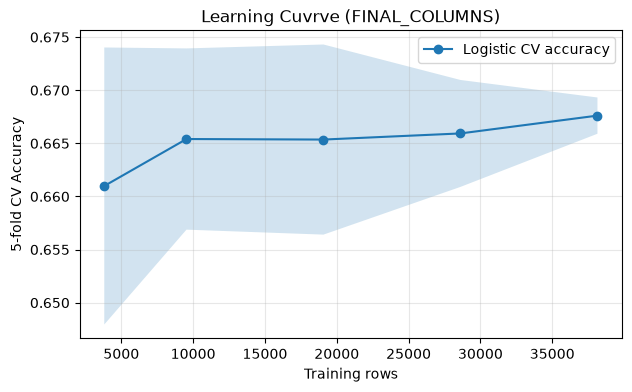

In [ ]:
# fractions = [0.1, 0.25, 0.5, 0.75, 1.0]
# sizes, means, stds = [], [], []

# parts = split_by_type(FINAL_COLUMNS)
# pipe = build_pipeline(build_preprocessor(parts['num']), clone(models['logistic']))

# for frac in fractions:
#     n = int(len(X_train) * frac)
#     X_sub = X_train.iloc[:n]
#     y_sub = y_train.iloc[:n]

#     scores = cross_val_score(pipe, X_sub, y_sub, cv=cv, scoring='accuracy', n_jobs=-1)
#     sizes.append(n)
#     means.append(scores.mean())
#     stds.append(scores.std())
#     print(f"{int(frac * 100):3d}% ({n:5d} rows) -> acc: {scores.mean():.4f} ± {scores.std():.4f}")
# means = np.array(means)
# stds = np.array(stds)

# plt.figure(figsize=(7, 4))
# plt.plot(sizes, means, marker='o', label='Logistic CV accuracy')
# plt.fill_between(sizes, means - stds, means + stds, alpha=0.2)
# plt.xlabel('Training rows')
# plt.ylabel('5-fold CV Accuracy')
# plt.title('Learning Cuvrve (FINAL_COLUMNS)')
# plt.grid(True, alpha=0.3)
# plt.legend()
# plt.show()


In [ ]:
def get_ensemble_proba(best_models_by_family, FINAL_COLUMNS, X_tr, y_tr, X_te):
    predictions_proba = []
    parts = split_by_type(FINAL_COLUMNS)
    for _, results in best_models_by_family.iterrows():
        model = clone(models[results['model']])
        preprocessor = build_preprocessor(parts['num'])
        pipeline = build_pipeline(preprocessor, model)
        pipeline.set_params(**results['params'])
        pipeline.fit(X_tr, y_tr)
        prediction_proba = pipeline.predict_proba(X_te)[:,1]
        predictions_proba.append(prediction_proba)
    avg_proba = np.mean(predictions_proba, axis=0)
    return avg_proba

def make_submission(best_models_by_family, FINAL_COLUMNS, X_tr, y_tr, X_te, test_id):
    avg_proba = get_ensemble_proba(best_models_by_family, FINAL_COLUMNS, X_tr, y_tr, X_te)
    ensemble_prediction = (avg_proba > 0.5).astype(int)
    submission = pd.DataFrame({'game_id': test_id, 'white_won': ensemble_prediction})
    submission.to_csv('./data/submission.csv', index=False)
    return avg_proba

In [ ]:
submission = pd.read_csv('./data/submission.csv')
comparison = df_test[['game_id', 'white_won']].merge(
    submission[['game_id', 'white_won']],
    on='game_id',
    suffixes=('_true', '_pred'),
    validate='one_to_one'
    
)
y_true = comparison['white_won_true']
y_pred = comparison['white_won_pred']
print("Accuracy:", accuracy_score(y_true, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred))


Accuracy: 0.7117662542774414
Confusion matrix:
 [[1281  522]
 [ 573 1423]]
              precision    recall  f1-score   support

           0       0.69      0.71      0.70      1803
           1       0.73      0.71      0.72      1996

    accuracy                           0.71      3799
   macro avg       0.71      0.71      0.71      3799
weighted avg       0.71      0.71      0.71      3799



In [24]:
pred = np.where(df_test['elo_diff'] > 0, 1, 0)
print('baseline rating:', (pred == y_test).mean())
print('selalu putih menang:', y_test.mean())

baseline rating: 0.63374226696026
selalu putih menang: 0.5134738387333543


In [ ]:
# n_moves_arr = [5, 10, 15, 20]
# cutoff_cols = FINAL_COLUMNS

In [ ]:

# results = []

# for n in n_moves_arr:
#     t0 = time.time()
#     d = pd.read_csv(f'games_2017-04m{n}.csv')
#     pipeline = build_pipeline(build_preprocessor(cutoff_cols), clone(models['logistic']))
#     threshold_cut = int(0.8 * len(d))
#     tr, te = d.iloc[:threshold_cut], d.iloc[threshold_cut:]
#     pipeline.fit(tr[cutoff_cols], tr['white_won'])
#     probs = pipeline.predict_proba(te[cutoff_cols])[:, 1]
    
#     predictions = (probs > 0.5).astype(int)
#     baseline_predict = np.where(te['elo_diff'] > 0, 1, 0)
#     baseline_acc = accuracy_score(te['white_won'], baseline_predict)
#     n_acc = accuracy_score(te['white_won'], predictions)
#     log_predict_acc = log_loss(te['white_won'], probs)
    
#     n_moves_description = {
#         'n_moves': n,
#         'time_took': time.time() - t0,
#         'baseline_acc': baseline_acc,
#         'accuracy': n_acc,
#         'accuracy_diff': np.abs(n_acc - baseline_acc),
#         'log_loss': log_predict_acc,
#     }
    
#     results.append(n_moves_description)
    
# results = pd.DataFrame(results)

In [24]:
results

,n_moves,time_took,baseline_acc,accuracy,accuracy_diff,log_loss
0,5,0.167090,0.636722,0.641713,0.004991,0.613965
1,10,0.169349,0.637057,0.677004,0.039947,0.589330
2,15,0.152672,0.640432,0.708344,0.067913,0.555898
3,20,0.139687,0.633122,0.748547,0.115425,0.508478


C:\Users\yazid\AppData\Local\Temp\ipykernel_12260\914526172.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1].legend()


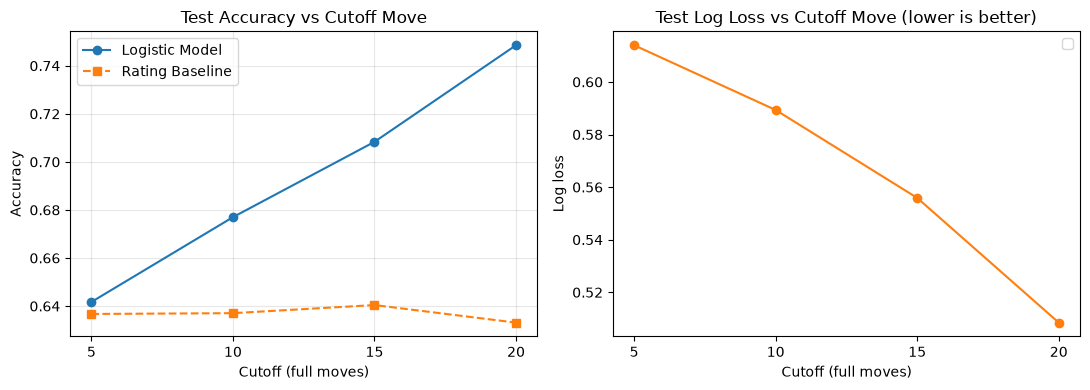

In [ ]:
# fig, axes = plt.subplots(1, 2, figsize=(11,4))
# axes[0].plot(results['n_moves'], results['accuracy'], marker='o', label='Logistic Model')
# axes[0].plot(results['n_moves'], results['baseline_acc'], marker='s', linestyle='--', label='Rating Baseline')
# axes[0].set_title('Test Accuracy vs Cutoff Move')
# axes[0].set_xlabel('Cutoff (full moves)')
# axes[0].set_ylabel('Accuracy')
# axes[0].set_xticks(n_moves_arr)
# axes[0].legend()
# axes[0].grid(True, alpha=0.3)

# axes[1].plot(results['n_moves'], results['log_loss'], marker='o', color='tab:orange')
# axes[1].set_title('Test Log Loss vs Cutoff Move (lower is better)')
# axes[1].set_xlabel('Cutoff (full moves)')
# axes[1].set_ylabel('Log loss')
# axes[1].set_xticks(n_moves_arr)
# axes[1].legend()
# axes[0].grid(True, alpha=0.3)

# plt.tight_layout()
# plt.show()




== LOGISTIC (Move 20) ==
 Raw eval_end       | acc: 0.7485 | log_loss: 0.5085
 Sigmoid eval_prob  | acc: 0.7462 | log_loss: 0.5102
 Both               | acc: 0.7483 | log_loss: 0.5094
 Eval_end + Has_increment | acc: 0.7483 | log_loss: 0.5085
 Eval_end + log_base_sec | acc: 0.7504 | log_loss: 0.5086
 Eval_end + Has_increment + log_base_sec | acc: 0.7501 | log_loss: 0.5086

== CATBOOST (Move 20) ==
 Raw eval_end       | acc: 0.7491 | log_loss: 0.5011
 Sigmoid eval_prob  | acc: 0.7491 | log_loss: 0.5011
 Both               | acc: 0.7459 | log_loss: 0.5014
 Eval_end + Has_increment | acc: 0.7501 | log_loss: 0.4998
 Eval_end + log_base_sec | acc: 0.7470 | log_loss: 0.5007
 Eval_end + Has_increment + log_base_sec | acc: 0.7472 | log_loss: 0.4993


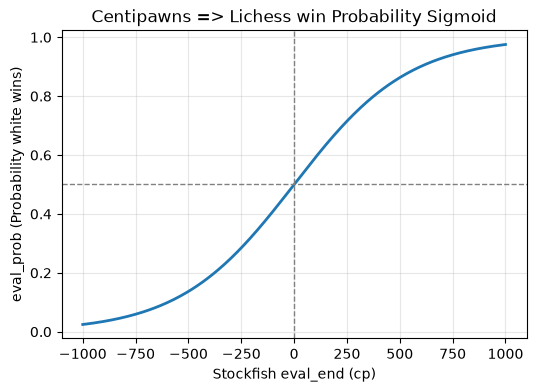

In [ ]:
# d_20 = pd.read_csv('games_2017-04m20.csv')
# d_20 = d_20.replace([np.inf, -np.inf], np.nan)
# d_20 = d_20.sort_values(by=['date', 'time']).reset_index(drop=True)
# d_20['eval_prob'] = 1 / (1 + np.exp(-0.00368208 * d_20['eval_end']))
# d_20['has_increment'] = (d_20['inc_sec'] > 0).astype(int)
# d_20['log_base_sec'] = np.log1p(d_20['base_sec'])

# cut_20 = int(len(d_20) * 0.8)
# tr_20, te_20 = d_20.iloc[:cut_20], d_20.iloc[cut_20:]

# base_cols = ['elo_diff', 'material_diff', 'white_clock', 'black_clock', 'clock_diff', 'white_clock_rel', 'black_clock_rel', 'clock_diff_rel']

# variants = [('Raw eval_end', ['eval_end']),
#             ('Sigmoid eval_prob', ['eval_prob']),
#             ('Both', ['eval_end', 'eval_prob']),
#             ('Eval_end + Has_increment', ['eval_end', 'has_increment']),
#             ('Eval_end + log_base_sec', ['eval_end', 'log_base_sec']),
#             ('Eval_end + Has_increment + log_base_sec', ['eval_end', 'log_base_sec', 'has_increment'])]

# for model_name in ['logistic', 'catboost']:
#     print(f'\n== {model_name.upper()} (Move 20) ==')
#     for label, eval_col in variants:  
#         cols = base_cols + eval_col
#         pipe = build_pipeline(build_preprocessor(cols), clone(models[model_name]))
#         pipe.fit(tr_20[cols], tr_20['white_won'])
#         probs = pipe.predict_proba(te_20[cols])[:, 1]
#         acc = accuracy_score(te_20['white_won'], (probs > 0.5).astype(int))
#         ll = log_loss(te_20['white_won'], probs)
#         print(f" {label:18s} | acc: {acc:.4f} | log_loss: {ll:.4f}")
# cp_grid = np.linspace(-1000, 1000, 400)
# prob_grid = 1 / (1 + np.exp(-0.00368208 * cp_grid))
# plt.figure(figsize=(6,4))
# plt.plot(cp_grid, prob_grid, linewidth=2)
# plt.axhline(0.5, color='gray', linestyle='--', linewidth=1)
# plt.axvline(0, color='gray', linestyle='--', linewidth=1)
# plt.title('Centipawns => Lichess win Probability Sigmoid')
# plt.xlabel('Stockfish eval_end (cp)')
# plt.ylabel('eval_prob (Probability white wins)')
# plt.grid(True, alpha=0.3)
# plt.show()
    